Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Training labels: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Validation labels: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Testing labels: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6436 - loss: 1.0775
Epoch 1: val_accuracy improved from None to 0.87232, saving model to resnet101_brain_tumor_best.keras

Epoch 1: finished saving model to resnet101_brain_tumor_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 280s 2s/step - accuracy: 0.7594 - loss: 0.6680 - val_accuracy: 0.8723 - val_loss: 0.3505
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.8504 - loss: 0.3887
Epoch 2: val_accuracy improved from 0.87232 to 0.88661, saving model to resnet101_brain_tumor_best.keras

Epoch 2: finished saving model to resnet101_brain_tumor_best.keras
140/1

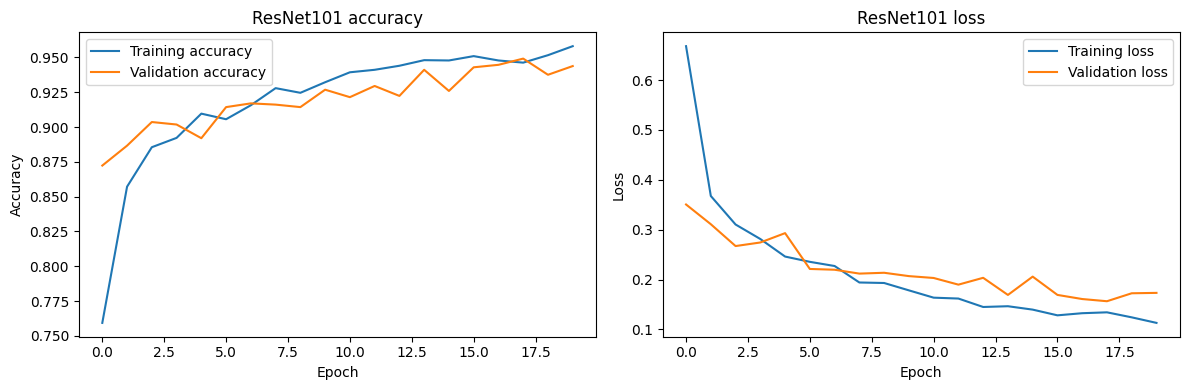

50/50 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.9031 - loss: 0.4634
Test loss: 0.4634
Test accuracy: 90.31%
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 148ms/step
\nClassification report:
              precision    recall  f1-score   support

      glioma       0.93      0.76      0.83       400
  meningioma       0.85      0.88      0.87       400
     notumor       0.88      1.00      0.93       400
   pituitary       0.96      0.98      0.97       400

    accuracy                           0.90      1600
   macro avg       0.91      0.90      0.90      1600
weighted avg       0.91      0.90      0.90      1600



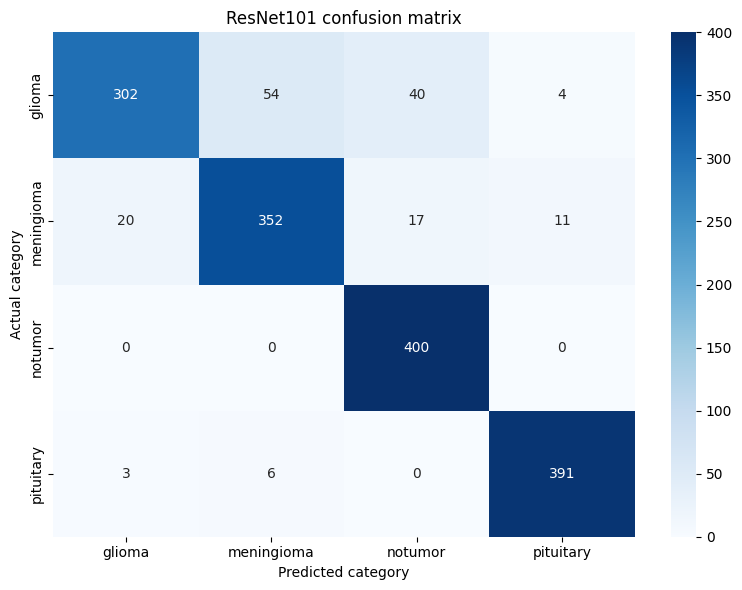

In [2]:
# 1. Import the tools we need
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet101, preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

# 2. Tell the notebook where the dataset folders are
# In Kaggle, attach the Brain Tumor MRI dataset first.
train_path = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training"
test_path = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing"

# 3. Prepare images for training.
# The training images get small changes (augmentation) to help the model learn.
# preprocess_input is the image format expected by this pretrained model.
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

# Validation images are not randomly changed.
validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

# The final test images are kept separate until the end.
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# 4. Load the images from their folders.
# The folder names become the class labels automatically.
train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42
)

validation_generator = validation_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

# Check that the folders have the same class order.
print("Training labels:", train_generator.class_indices)
print("Validation labels:", validation_generator.class_indices)
print("Testing labels:", test_generator.class_indices)

assert train_generator.class_indices == validation_generator.class_indices
assert train_generator.class_indices == test_generator.class_indices

# 5. Load the pretrained ResNet101 model.
# include_top=False removes its original ImageNet classification layers.
base_model = ResNet101(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers for this first learning project.
# This means we train the new classification layers, not the whole model.
base_model.trainable = False

# Add our own layers to predict the four brain-MRI dataset categories.
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(train_generator.num_classes, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

# 6. Tell the model how to learn.
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best version based on validation accuracy.
checkpoint = ModelCheckpoint(
    "resnet101_brain_tumor_best.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

# Stop if validation loss does not improve for five epochs.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# 7. Train the model.
# The validation folder is taken from Training, not from the final Testing folder.
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[checkpoint, early_stopping]
)

# 8. Show how accuracy and loss changed while learning.
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("ResNet101 accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("ResNet101 loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# 9. Final evaluation: use the separate test folder only now.
# Load the best checkpoint saved during training.
best_model = tf.keras.models.load_model("resnet101_brain_tumor_best.keras")

test_loss, test_accuracy = best_model.evaluate(test_generator, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# 10. See which categories the model predicted correctly or incorrectly.
test_generator.reset()
predictions = best_model.predict(test_generator, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)
true_labels = test_generator.classes
class_names = list(test_generator.class_indices.keys())

print("\\nClassification report:")
print(classification_report(
    true_labels,
    predicted_labels,
    target_names=class_names,
    zero_division=0
))

confusion = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("ResNet101 confusion matrix")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.tight_layout()
plt.show()